## H&M EDA

1. Анализ данных
2. Система рекомендаций, основанная на похожести клиентов (Collaborative filtering)

<img src='https://upload.wikimedia.org/wikipedia/commons/5/53/H%26M-Logo.svg' width=500>

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib import pyplot as plt
from tqdm import tqdm
from pathlib import Path

https://www.kaggle.com/competitions/h-and-m-personalized-fashion-recommendations

In [2]:
!wget 'https://drive.google.com/uc?id=1R_v1aeFQGConcEwoVCWk79iJeZ6-xyKI' -O articles.csv

--2026-10-13 01:49:52--  https://drive.google.com/uc?id=1R_v1aeFQGConcEwoVCWk79iJeZ6-xyKI
Resolving drive.google.com (drive.google.com)... 192.178.239.139, 192.178.239.113, 192.178.239.100, ...
Connecting to drive.google.com (drive.google.com)|192.178.239.139|:443... connected.
HTTP request sent, awaiting response... 303 See Other
Location: https://drive.usercontent.google.com/download?id=1R_v1aeFQGConcEwoVCWk79iJeZ6-xyKI [following]
--2026-10-13 01:49:52--  https://drive.usercontent.google.com/download?id=1R_v1aeFQGConcEwoVCWk79iJeZ6-xyKI
Resolving drive.usercontent.google.com (drive.usercontent.google.com)... 172.217.203.132, 2607:f8b0:400c:c07::84
Connecting to drive.usercontent.google.com (drive.usercontent.google.com)|172.217.203.132|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 28427845 (27M) [application/octet-stream]
Saving to: ‘articles.csv’

articles.csv        100%[===================>]  27.11M  82.8MB/s    in 0.3s    

2026-10-13 01:49:54 (82.8 M

In [3]:
!wget -O customers.csv "https://drive.usercontent.google.com/download?id=1wK-n8XBUc1-M-tAiJdkkSQcL2ajf5Lbm&export=download&confirm=t"

--2026-10-13 01:49:56--  https://drive.usercontent.google.com/download?id=1wK-n8XBUc1-M-tAiJdkkSQcL2ajf5Lbm&export=download&confirm=t
Resolving drive.usercontent.google.com (drive.usercontent.google.com)... 172.217.203.132, 2607:f8b0:400c:c07::84
Connecting to drive.usercontent.google.com (drive.usercontent.google.com)|172.217.203.132|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 207045324 (197M) [application/octet-stream]
Saving to: ‘customers.csv’

customers.csv       100%[===================>] 197.45M  96.4MB/s    in 2.0s    

2026-10-13 01:49:59 (96.4 MB/s) - ‘customers.csv’ saved [207045324/207045324]



In [ ]:
# !wget --load-cookies /tmp/cookies.txt "https://docs.google.com/uc?export=download&confirm=$(wget --quiet --save-cookies /tmp/cookies.txt --keep-session-cookies --no-check-certificate 'https://docs.google.com/uc?export=download&id=1wK-n8XBUc1-M-tAiJdkkSQcL2ajf5Lbm' -O- | sed -rn 's/.*confirm=([0-9A-Za-z_]+).*/\1\n/p')&id=1wK-n8XBUc1-M-tAiJdkkSQcL2ajf5Lbm" -O customers.csv && rm -rf /tmp/cookies.txt

--2026-10-12 15:40:05--  https://docs.google.com/uc?export=download&confirm=&id=1wK-n8XBUc1-M-tAiJdkkSQcL2ajf5Lbm
Resolving docs.google.com (docs.google.com)... 108.177.121.138, 108.177.121.100, 108.177.121.139, ...
Connecting to docs.google.com (docs.google.com)|108.177.121.138|:443... connected.
HTTP request sent, awaiting response... 303 See Other
Location: https://drive.usercontent.google.com/download?id=1wK-n8XBUc1-M-tAiJdkkSQcL2ajf5Lbm&export=download [following]
--2026-10-12 15:40:05--  https://drive.usercontent.google.com/download?id=1wK-n8XBUc1-M-tAiJdkkSQcL2ajf5Lbm&export=download
Resolving drive.usercontent.google.com (drive.usercontent.google.com)... 173.194.64.132, 2607:f8b0:4001:c6a::84
Connecting to drive.usercontent.google.com (drive.usercontent.google.com)|173.194.64.132|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 2463 (2.4K) [text/html]
Saving to: ‘customers.csv’

customers.csv       100%[===================>]   2.41K  --.-KB/s    in 0s  

In [54]:
!wget -O transactions.csv "https://drive.usercontent.google.com/download?id=1jz2hHg7iwxSAnAisnlQyiPwV2a8ZG_sB&export=download&confirm=t"

--2026-10-13 02:24:43--  https://drive.usercontent.google.com/download?id=1jz2hHg7iwxSAnAisnlQyiPwV2a8ZG_sB&export=download&confirm=t
Resolving drive.usercontent.google.com (drive.usercontent.google.com)... 172.217.203.132, 2607:f8b0:400c:c07::84
Connecting to drive.usercontent.google.com (drive.usercontent.google.com)|172.217.203.132|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 3488002253 (3.2G) [application/octet-stream]
Saving to: ‘transactions.csv’

transactions.csv    100%[===================>]   3.25G  78.2MB/s    in 43s     

2026-10-13 02:25:27 (76.6 MB/s) - ‘transactions.csv’ saved [3488002253/3488002253]



In [ ]:
# !wget --load-cookies /tmp/cookies.txt "https://docs.google.com/uc?export=download&confirm=$(wget --quiet --save-cookies /tmp/cookies.txt --keep-session-cookies --no-check-certificate 'https://docs.google.com/uc?export=download&id=1jz2hHg7iwxSAnAisnlQyiPwV2a8ZG_sB' -O- | sed -rn 's/.*confirm=([0-9A-Za-z_]+).*/\1\n/p')&id=1jz2hHg7iwxSAnAisnlQyiPwV2a8ZG_sB" -O transactions.csv && rm -rf /tmp/cookies.txt

--2026-10-13 01:50:19--  https://docs.google.com/uc?export=download&confirm=&id=1jz2hHg7iwxSAnAisnlQyiPwV2a8ZG_sB
Resolving docs.google.com (docs.google.com)... 142.251.107.101, 142.251.107.100, 142.251.107.138, ...
Connecting to docs.google.com (docs.google.com)|142.251.107.101|:443... connected.
HTTP request sent, awaiting response... 303 See Other
Location: https://drive.usercontent.google.com/download?id=1jz2hHg7iwxSAnAisnlQyiPwV2a8ZG_sB&export=download [following]
--2026-10-13 01:50:19--  https://drive.usercontent.google.com/download?id=1jz2hHg7iwxSAnAisnlQyiPwV2a8ZG_sB&export=download
Resolving drive.usercontent.google.com (drive.usercontent.google.com)... 172.217.203.132, 2607:f8b0:400c:c07::84
Connecting to drive.usercontent.google.com (drive.usercontent.google.com)|172.217.203.132|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 2470 (2.4K) [text/html]
Saving to: ‘transactions.csv’

transactions.csv    100%[===================>]   2.41K  --.-KB/s    in

In [55]:
articles = pd.read_csv("articles.csv")
customers = pd.read_csv("customers.csv")
transactions = pd.read_csv("transactions.csv")

## Articles

Эта таблица содержит все h&m артикулы.

> `article_id` : Уникальный идентификатор артикула   
> `prod_name` : Имя продукта <br>
> `product_type_name` : Тип товара   
> `index_name`: Подраздел  
> `index_group_name` : Раздел  
> `section_name`: Секция  
> `garment_group_name`: Категория товара  
> `detail_desc`: Детали  

In [56]:
articles.head()

,article_id,prod_name,product_type_name,product_group_name,graphical_appearance_name,colour_group_name,index_name,index_group_name,section_name,garment_group_name,detail_desc
0,108775015,Strap top,Vest top,Garment Upper body,Solid,Black,Ladieswear,Ladieswear,Womens Everyday Basics,Jersey Basic,Jersey top with narrow shoulder straps.
1,108775044,Strap top,Vest top,Garment Upper body,Solid,White,Ladieswear,Ladieswear,Womens Everyday Basics,Jersey Basic,Jersey top with narrow shoulder straps.
2,108775051,Strap top (1),Vest top,Garment Upper body,Stripe,Off White,Ladieswear,Ladieswear,Womens Everyday Basics,Jersey Basic,Jersey top with narrow shoulder straps.
3,110065001,OP T-shirt (Idro),Bra,Underwear,Solid,Black,Lingeries/Tights,Ladieswear,Womens Lingerie,"Under-, Nightwear","Microfibre T-shirt bra with underwired, moulde..."
4,110065002,OP T-shirt (Idro),Bra,Underwear,Solid,White,Lingeries/Tights,Ladieswear,Womens Lingerie,"Under-, Nightwear","Microfibre T-shirt bra with underwired, moulde..."


Таблица с количеством уникальных значений в каждой колонке

In [57]:
for col in articles.columns:
    if not 'no' in col and not 'code' in col and not 'id' in col:
        un_n = articles[col].nunique()
        print(f'no of unique {col}: {un_n}')

no of unique prod_name: 45875
no of unique product_type_name: 131
no of unique product_group_name: 19
no of unique graphical_appearance_name: 30
no of unique colour_group_name: 50
no of unique index_name: 10
no of unique index_group_name: 5
no of unique section_name: 56
no of unique garment_group_name: 21
no of unique detail_desc: 43404


**Анализ категории товара**

Divided - молодежная и более дешевая одежда

In [58]:
articles['index_name'].value_counts()

,count
index_name,
Ladieswear,26001
Divided,15149
Menswear,12553
Children Sizes 92-140,12007
Children Sizes 134-170,9214
Baby Sizes 50-98,8875
Ladies Accessories,6961
Lingeries/Tights,6775
"Children Accessories, Swimwear",4615


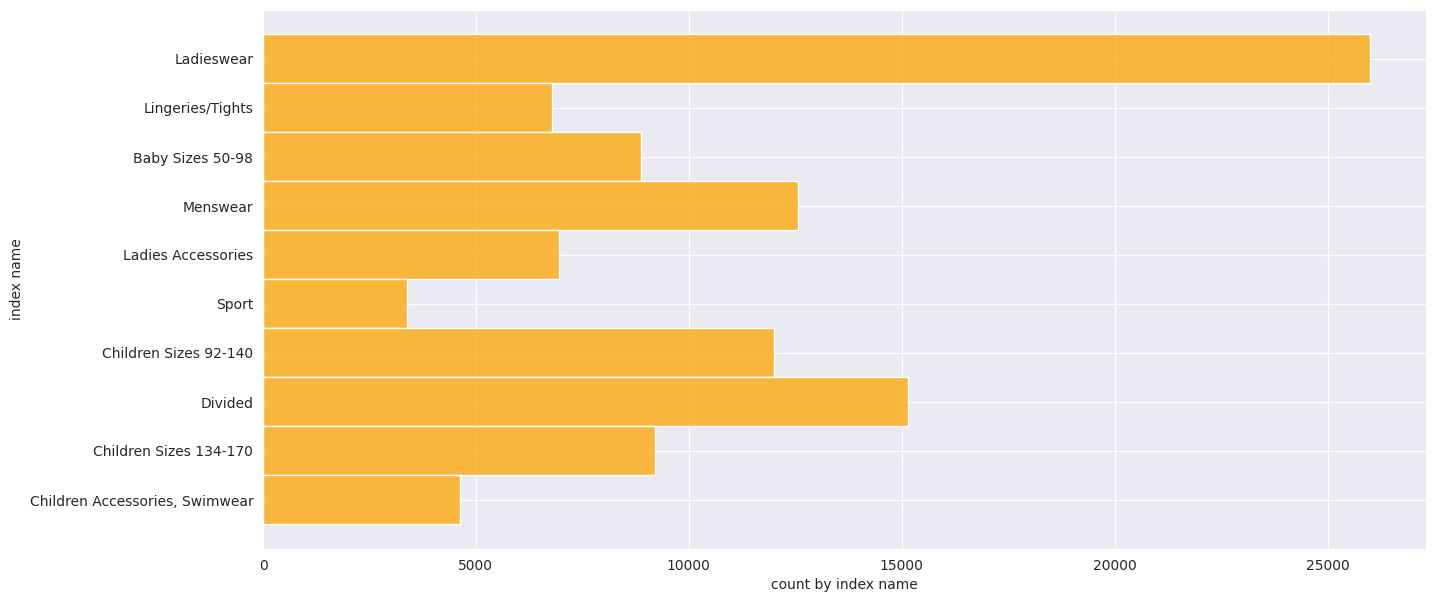

In [59]:
f, ax = plt.subplots(figsize=(15, 7))
ax = sns.histplot(data=articles, y='index_name', color='orange')
ax.set_xlabel('count by index name')
ax.set_ylabel('index name')
plt.show()

**Анализ категории товара в зависимости от раздела**

In [60]:
articles[['garment_group_name', 'index_group_name']].head()

,garment_group_name,index_group_name
0,Jersey Basic,Ladieswear
1,Jersey Basic,Ladieswear
2,Jersey Basic,Ladieswear
3,"Under-, Nightwear",Ladieswear
4,"Under-, Nightwear",Ladieswear


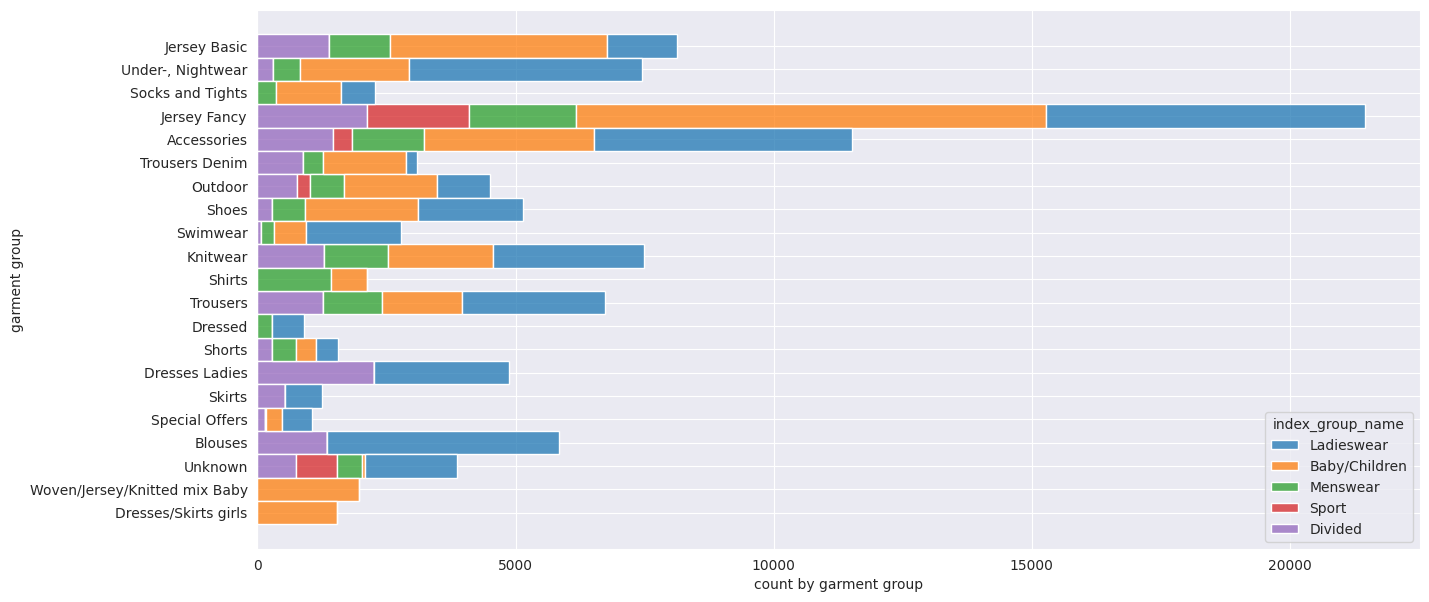

In [61]:
f, ax = plt.subplots(figsize=(15, 7))
ax = sns.histplot(data=articles, y='garment_group_name', color='orange', hue='index_group_name', multiple="stack")
ax.set_xlabel('count by garment group')
ax.set_ylabel('garment group')
plt.show()

- Jersey fancy - самый популярный, особенно для женщин и детей (обычная базовая одежда)
- Аксессуары - вторая по популярности категория, скорее всего из-за своей стоимости

Можно обратить внимание, что раздел еще может делиться на подраздел

In [62]:
articles.groupby(['index_group_name', 'index_name']).count()['article_id']

index_group_name  index_name                    
Baby/Children     Baby Sizes 50-98                   8875
                  Children Accessories, Swimwear     4615
                  Children Sizes 134-170             9214
                  Children Sizes 92-140             12007
Divided           Divided                           15149
Ladieswear        Ladies Accessories                 6961
                  Ladieswear                        26001
                  Lingeries/Tights                   6775
Menswear          Menswear                          12553
Sport             Sport                              3392
Name: article_id, dtype: int64

Изучаем разнообразие именований товаров в каждой категории товара.

In [63]:
pd.options.display.max_rows = None
articles.groupby(['product_group_name', 'product_type_name']).count()['article_id']

product_group_name     product_type_name       
Accessories            Accessories set                 7
                       Alice band                      6
                       Baby Bib                        3
                       Bag                          1280
                       Beanie                         56
                       Belt                          458
                       Bracelet                      180
                       Braces                          3
                       Bucket hat                      7
                       Cap                            13
                       Cap/peaked                    573
                       Dog Wear                       20
                       Earring                      1159
                       Earrings                       11
                       Eyeglasses                      2
                       Felt hat                       10
                       Giftbox                        15
                       Gloves                        367
                       Hair clip                     244
                       Hair string                   238
                       Hair ties                      24
                       Hair/alice band               854
                       Hairband                        2
                       Hat/beanie                   1349
                       Hat/brim                      396
                       Headband                        1
                       Necklace                      581
                       Other accessories            1034
                       Ring                          240
                       Scarf                        1013
                       Soft Toys                      46
                       Straw hat                       6
                       Sunglasses                    621
                       Tie                           141
                       Umbrella                       26
                       Wallet                         77
                       Watch                          73
                       Waterbottle                    22
Bags                   Backpack                        6
                       Bumbag                          1
                       Cross-body bag                  5
                       Shoulder bag                    2
                       Tote bag                        2
                       Weekend/Gym bag                 9
Cosmetic               Chem. cosmetics                 3
                       Fine cosmetics                 46
Fun                    Toy                             2
Furniture              Side table                     13
Garment Full body      Costumes                       90
                       Dress                       10362
                       Dungarees                     309
                       Garment Set                  1320
                       Jumpsuit/Playsuit            1147
                       Outdoor overall                64
Garment Lower body     Leggings/Tights              1878
                       Outdoor trousers              130
                       Shorts                       3939
                       Skirt                        2696
                       Trousers                    11169
Garment Upper body     Blazer                       1110
                       Blouse                       3979
                       Bodysuit                      913
                       Cardigan                     1550
                       Coat                          460
                       Hoodie                       2356
                       Jacket                       3940
                       Outdoor Waistcoat             154
                       Polo shirt                    449
                       Shirt                        3405
                   

**Какого типа товаров больше**

In [64]:
top_item = articles.groupby(['product_type_name']).count()['article_id'].sort_values(ascending=False).iloc[:10]
top_item

,article_id
product_type_name,
Trousers,11169
Dress,10362
Sweater,9302
T-shirt,7904
Top,4155
Blouse,3979
Jacket,3940
Shorts,3939
Shirt,3405


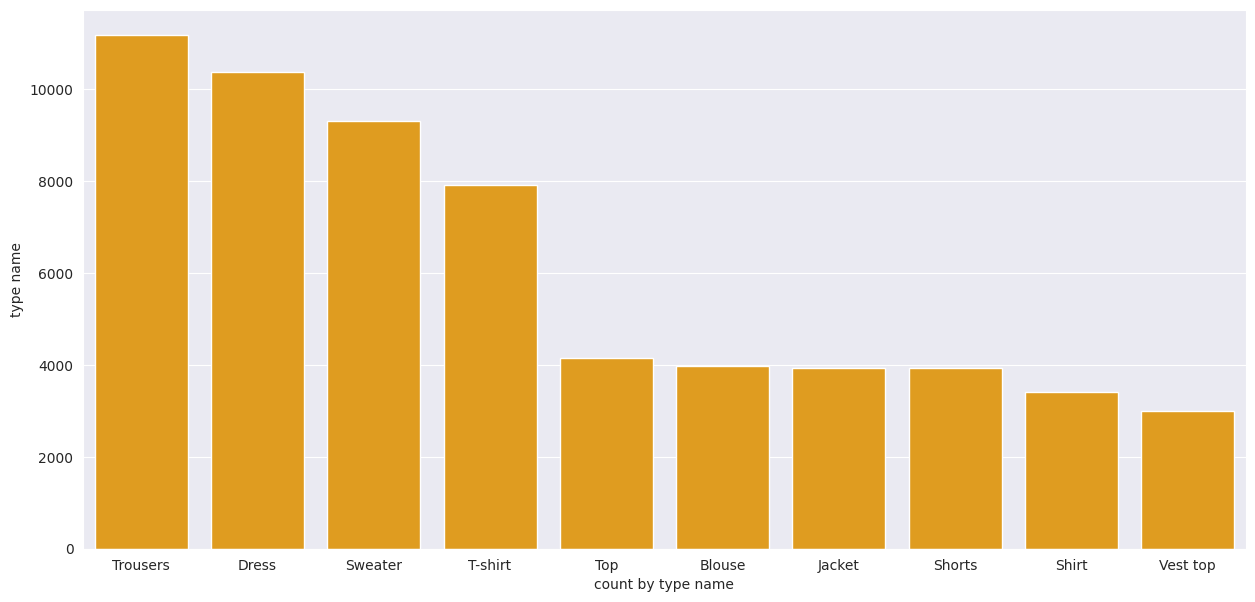

In [65]:
f, ax = plt.subplots(figsize=(15, 7))
ax = sns.barplot(x=top_item.index, y=top_item.values, color='orange')
ax.set_xlabel('count by type name')
ax.set_ylabel('type name')
plt.show()

**В какой категории товаров больше**

In [66]:
top_group = articles.groupby(['product_group_name']).count()['article_id'].sort_values(ascending=False).iloc[:10]
top_group

,article_id
product_group_name,
Garment Upper body,42741
Garment Lower body,19812
Garment Full body,13292
Accessories,11158
Underwear,5490
Shoes,5283
Swimwear,3127
Socks & Tights,2442
Nightwear,1899


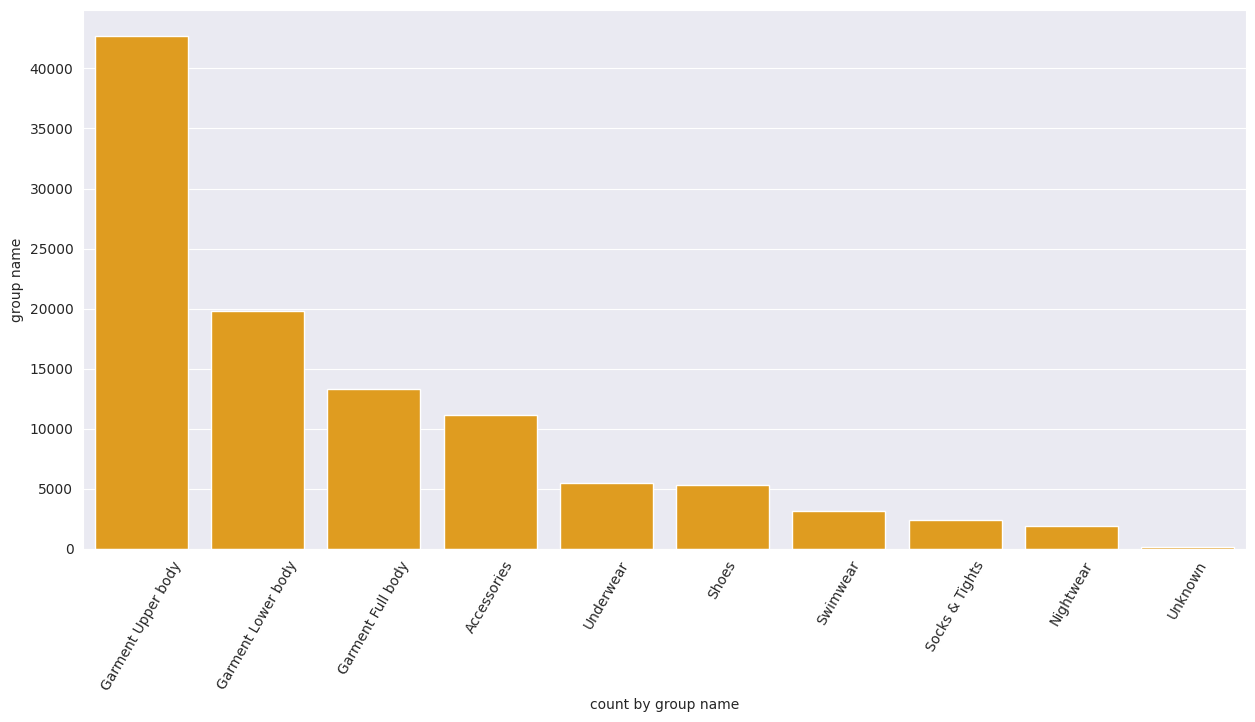

In [67]:
f, ax = plt.subplots(figsize=(15, 7))
sns.barplot(x=top_group.index, y=top_group.values, color='orange')
plt.xlabel('count by group name')
plt.ylabel('group name')
plt.xticks(np.arange(len(top_group.index)), top_group.index, rotation=60)
plt.show()

**Какой графический элемент присутствует чаще всего**

In [68]:
top_graph = articles.groupby(['graphical_appearance_name']).count()['article_id'].sort_values(ascending=False).iloc[:10]
top_graph

,article_id
graphical_appearance_name,
Solid,49747
All over pattern,17165
Melange,5938
Stripe,4990
Denim,4842
Front print,3215
Placement print,3098
Check,2178
Colour blocking,1830


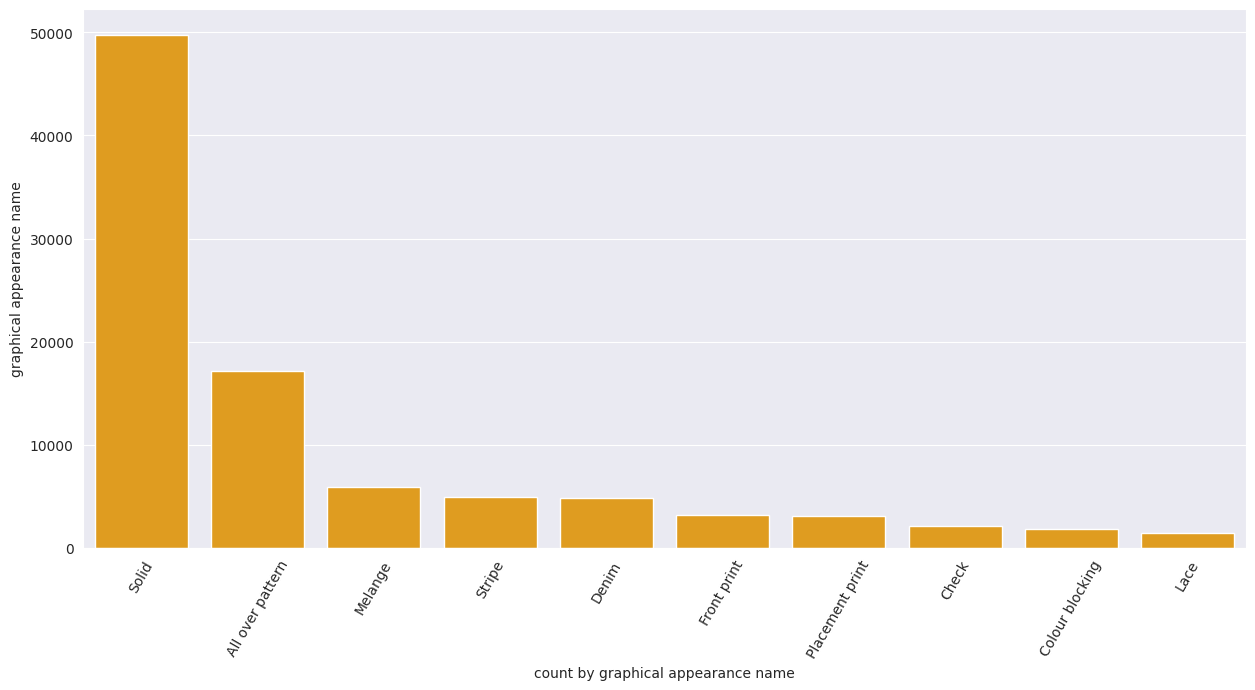

In [69]:
f, ax = plt.subplots(figsize=(15, 7))
sns.barplot(x=top_graph.index, y=top_graph.values, color='orange')
plt.xlabel('count by graphical appearance name')
plt.ylabel('graphical appearance name')
plt.xticks(np.arange(len(top_graph.index)), top_graph.index, rotation=60)
plt.show()

**Какой цвет присутствует чаще всего**

In [70]:
top_color = articles.groupby(['colour_group_name']).count()['article_id'].sort_values(ascending=False).iloc[:10]
top_color

,article_id
colour_group_name,
Black,22670
Dark Blue,12171
White,9542
Light Pink,5811
Grey,4487
Light Beige,3356
Blue,3308
Red,3056
Light Blue,3012


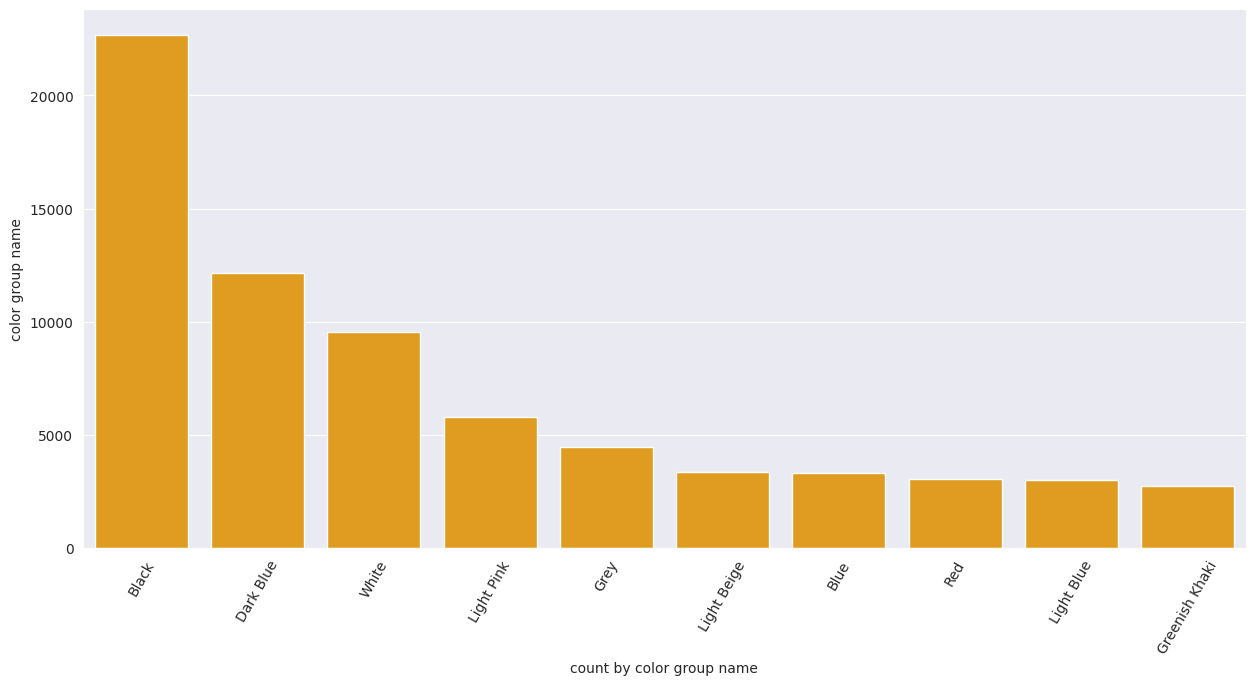

In [71]:
f, ax = plt.subplots(figsize=(15, 7))
sns.barplot(x=top_color.index, y=top_color.values, color='orange')
plt.xlabel('count by color group name')
plt.ylabel('color group name')
plt.xticks(np.arange(len(top_color.index)), top_color.index, rotation=60)
plt.show()

## Customers


> `customer_id` : Уникальный идентификатор клиента  
> `Active` : 1 или пропуск     
> `club_member_status` : Статус в клубе    
> `fashion_news_frequency` : Как часто H&M может присылать новости клиенту    
> `age` : Возраст клиента    
> `postal_code` : Почтовый индекс клиента

In [72]:
pd.options.display.max_rows = 50
customers.head()

,customer_id,Active,club_member_status,fashion_news_frequency,age,postal_code
0,00000dbacae5abe5e23885899a1fa44253a17956c6d1c3...,NaN,ACTIVE,NONE,49.0,52043ee2162cf5aa7ee79974281641c6f11a68d276429a...
1,0000423b00ade91418cceaf3b26c6af3dd342b51fd051e...,NaN,ACTIVE,NONE,25.0,2973abc54daa8a5f8ccfe9362140c63247c5eee03f1d93...
2,000058a12d5b43e67d225668fa1f8d618c13dc232df0ca...,NaN,ACTIVE,NONE,24.0,64f17e6a330a85798e4998f62d0930d14db8db1c054af6...
3,00005ca1c9ed5f5146b52ac8639a40ca9d57aeff4d1bd2...,NaN,ACTIVE,NONE,54.0,5d36574f52495e81f019b680c843c443bd343d5ca5b1c2...
4,00006413d8573cd20ed7128e53b7b13819fe5cfc2d801f...,1.0,ACTIVE,Regularly,52.0,25fa5ddee9aac01b35208d01736e57942317d756b32ddd...


In [73]:
customers.shape

(1371980, 6)

Таблица с количеством уникальных значений в каждой колонке

In [74]:
for col in customers.columns:
    un_n = customers[col].nunique()
    print(f'no of unique {col}: {un_n}')

no of unique customer_id: 1371980
no of unique Active: 1
no of unique club_member_status: 3
no of unique fashion_news_frequency: 3
no of unique age: 84
no of unique postal_code: 352899


Убедимся, что нет дубликатов в id клиентов

In [75]:
customers.shape[0] - customers['customer_id'].nunique()

0

У нас есть очень большое количество клиентов на одном индексе - 120303. Это может быть либо какой-то почтовый индекс, которым заполняют пропуски или же это может огромный распределительный центр или постамат

In [76]:
data_postal = customers.groupby('postal_code', as_index=False).count()[['postal_code', 'customer_id']].sort_values('customer_id', ascending=False)
data_postal.head()

,postal_code,customer_id
61034,2c29ae653a9282cce4151bd87643c907644e09541abc28...,120303
281937,cc4ed85e30f4977dae47662ddc468cd2eec11472de6fac...,261
156090,714976379549eb90aae4a71bca6c7402cc646ae7c40f6c...,159
171208,7c1fa3b0ec1d37ce2c3f34f63bd792f3b4494f324b6be5...,157
126228,5b7eb31eabebd3277de632b82267286d847fd5d44287ee...,156


При этом возраста, статус в клубе различны, как и айди клиента

In [77]:
data_postal['postal_code'].iloc[0]

'2c29ae653a9282cce4151bd87643c907644e09541abc28ae87dea0d1f6603b1c'

In [78]:
customers[customers['postal_code'] == '2c29ae653a9282cce4151bd87643c907644e09541abc28ae87dea0d1f6603b1c'].head(5)

,customer_id,Active,club_member_status,fashion_news_frequency,age,postal_code
5,000064249685c11552da43ef22a5030f35a147f723d5b0...,NaN,NaN,NaN,NaN,2c29ae653a9282cce4151bd87643c907644e09541abc28...
8,00007e8d4e54114b5b2a9b51586325a8d0fa74ea23ef77...,NaN,ACTIVE,NONE,20.0,2c29ae653a9282cce4151bd87643c907644e09541abc28...
9,00008469a21b50b3d147c97135e25b4201a8c58997f787...,NaN,ACTIVE,NONE,20.0,2c29ae653a9282cce4151bd87643c907644e09541abc28...
11,000097d91384a0c14893c09ed047a963c4fc6a5c021044...,NaN,ACTIVE,NONE,31.0,2c29ae653a9282cce4151bd87643c907644e09541abc28...
14,0000ae1bbb25e04bdc7e35f718e852adfb3fbb72ef38b3...,1.0,ACTIVE,Regularly,29.0,2c29ae653a9282cce4151bd87643c907644e09541abc28...


**Анализ вораста клиентов**

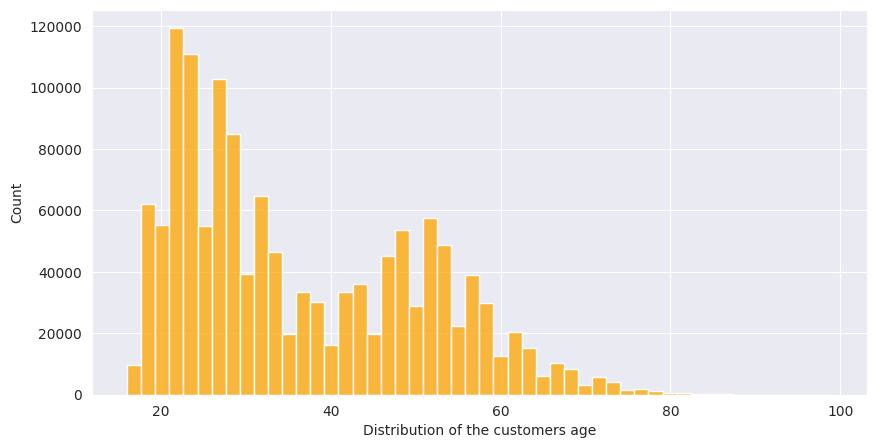

In [79]:
import seaborn as sns
from matplotlib import pyplot as plt


sns.set_style("darkgrid")
f, ax = plt.subplots(figsize=(10,5))

ax = sns.histplot(data=customers, x='age', bins=50, color='orange')
ax.set_xlabel('Distribution of the customers age')
plt.show()

**Анализ статуса в клубе H&M**

Практически все клиенты имеют активный статус, некоторые из них только начинают его активировать и совсем маленькая доля людей, которые вышли из клуба.

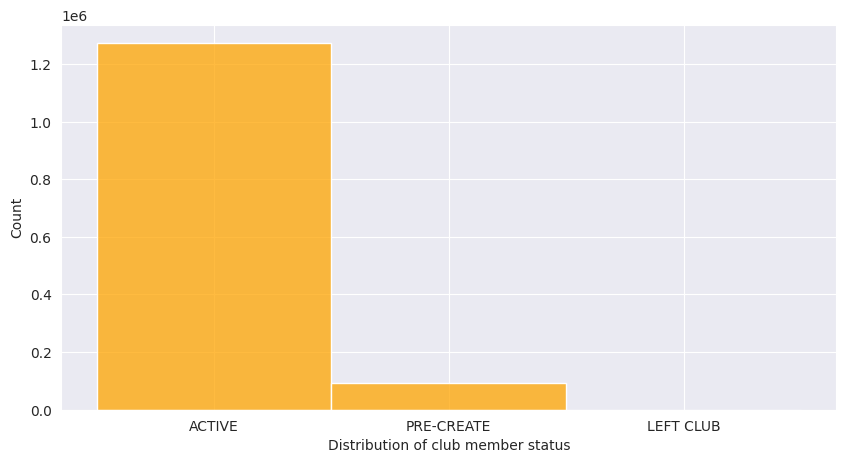

In [80]:
sns.set_style("darkgrid")
f, ax = plt.subplots(figsize=(10,5))
ax = sns.histplot(data=customers, x='club_member_status', color='orange')
ax.set_xlabel('Distribution of club member status')
plt.show()

**Анализ частоты отправки новостей**

In [81]:
customers['fashion_news_frequency'].unique()

array(['NONE', 'Regularly', nan, 'Monthly'], dtype=object)

In [82]:
customers.loc[~customers['fashion_news_frequency'].isin(['Regularly', 'Monthly'])]

,customer_id,Active,club_member_status,fashion_news_frequency,age,postal_code
0,00000dbacae5abe5e23885899a1fa44253a17956c6d1c3...,NaN,ACTIVE,NONE,49.0,52043ee2162cf5aa7ee79974281641c6f11a68d276429a...
1,0000423b00ade91418cceaf3b26c6af3dd342b51fd051e...,NaN,ACTIVE,NONE,25.0,2973abc54daa8a5f8ccfe9362140c63247c5eee03f1d93...
2,000058a12d5b43e67d225668fa1f8d618c13dc232df0ca...,NaN,ACTIVE,NONE,24.0,64f17e6a330a85798e4998f62d0930d14db8db1c054af6...
3,00005ca1c9ed5f5146b52ac8639a40ca9d57aeff4d1bd2...,NaN,ACTIVE,NONE,54.0,5d36574f52495e81f019b680c843c443bd343d5ca5b1c2...
5,000064249685c11552da43ef22a5030f35a147f723d5b0...,NaN,NaN,NaN,NaN,2c29ae653a9282cce4151bd87643c907644e09541abc28...
...,...,...,...,...,...,...
1371968,ffff4c4e8b57b633c1ddf8fbd53db16b962cf831baf9ed...,NaN,ACTIVE,NONE,40.0,3b4a300713f8b142836a67caa5b6d5b3f10a7650c06820...
1371972,ffff8f9ecdce722b5bab97fff68a6d1866492209bfe524...,NaN,ACTIVE,NONE,52.0,0de9d1ec7dc785301ca5fbe8949cfc2cfbd77e7a807270...
1371975,ffffbbf78b6eaac697a8a5dfbfd2bfa8113ee5b403e474...,NaN,ACTIVE,NONE,24.0,7aa399f7e669990daba2d92c577b52237380662f36480b...
1371976,ffffcd5046a6143d29a04fb8c424ce494a76e5cdf4fab5...,NaN,ACTIVE,NONE,21.0,3f47f1279beb72215f4de557d950e0bfa73789d24acb5e...


In [83]:
customers.loc[~customers['fashion_news_frequency'].isin(['Regularly', 'Monthly']), 'fashion_news_frequency'] = 'None'
customers['fashion_news_frequency'].unique()

array(['None', 'Regularly', 'Monthly'], dtype=object)

In [84]:
pie_data = customers[['customer_id', 'fashion_news_frequency']].groupby('fashion_news_frequency').count()
pie_data

,customer_id
fashion_news_frequency,
Monthly,842
None,893722
Regularly,477416


Клиенты предпочитают не получать никаких новостей.

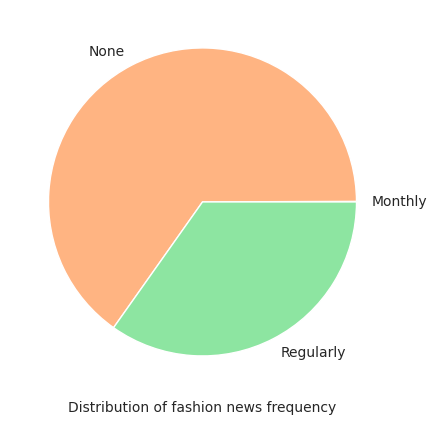

In [85]:
sns.set_style("darkgrid")
f, ax = plt.subplots(figsize=(10,5))

colors = sns.color_palette('pastel')
ax.pie(pie_data.customer_id, labels=pie_data.index, colors = colors)
ax.set_facecolor('lightgrey')
ax.set_xlabel('Distribution of fashion news frequency')
plt.show()

## Transactions

> `t_dat` : Время покупки    
> `customer_id` : Уникальный идентификатор клиента    
> `article_id` : Уникальный идентификатор артикула  
> `price` : Стоимость покупок    
> `sales_channel_id` : Канал продажи

In [86]:
transactions.head()

,t_dat,customer_id,article_id,price,sales_channel_id
0,2018-09-20,000058a12d5b43e67d225668fa1f8d618c13dc232df0ca...,663713001,0.050831,2
1,2018-09-20,000058a12d5b43e67d225668fa1f8d618c13dc232df0ca...,541518023,0.030492,2
2,2018-09-20,00007d2de826758b65a93dd24ce629ed66842531df6699...,505221004,0.015237,2
3,2018-09-20,00007d2de826758b65a93dd24ce629ed66842531df6699...,685687003,0.016932,2
4,2018-09-20,00007d2de826758b65a93dd24ce629ed66842531df6699...,685687004,0.016932,2


**Поиск выбросов в стоимости покупок**

In [87]:
pd.set_option('display.float_format', '{:.4f}'.format)
transactions.describe()['price']

,price
count,31788324.0000
mean,0.0278
std,0.0192
min,0.0000
25%,0.0158
50%,0.0254
75%,0.0339
max,0.5915


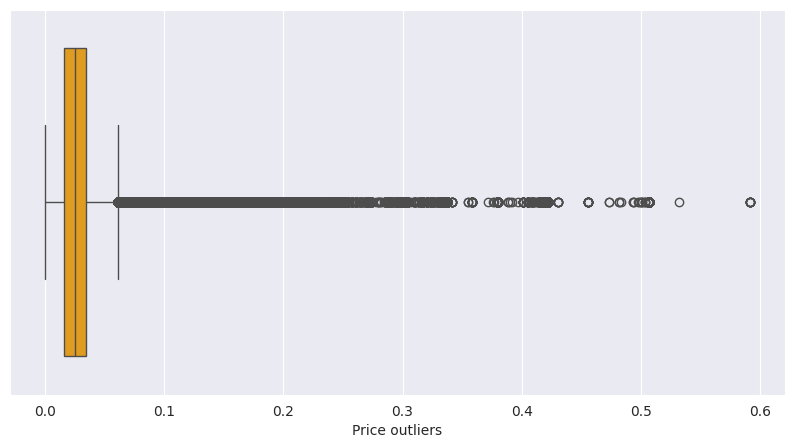

In [88]:
sns.set_style("darkgrid")
f, ax = plt.subplots(figsize=(10,5))
ax = sns.boxplot(data=transactions, x='price', color='orange')
ax.set_xlabel('Price outliers')
plt.show()

Но кстати, анализировать стоимости внутри групп - это более правильно, т.к. цены аксессуаров и брюк могут отличаться.

In [91]:
articles_for_merge = articles[['article_id', 'prod_name', 'product_type_name', 'product_group_name', 'index_name']]
articles_for_merge.head()

,article_id,prod_name,product_type_name,product_group_name,index_name
0,108775015,Strap top,Vest top,Garment Upper body,Ladieswear
1,108775044,Strap top,Vest top,Garment Upper body,Ladieswear
2,108775051,Strap top (1),Vest top,Garment Upper body,Ladieswear
3,110065001,OP T-shirt (Idro),Bra,Underwear,Lingeries/Tights
4,110065002,OP T-shirt (Idro),Bra,Underwear,Lingeries/Tights


In [92]:
articles_for_merge = transactions[['customer_id', 'article_id', 'price', 't_dat']].merge(articles_for_merge, on='article_id', how='left')
articles_for_merge

,customer_id,article_id,price,t_dat,prod_name,product_type_name,product_group_name,index_name
0,000058a12d5b43e67d225668fa1f8d618c13dc232df0ca...,663713001,0.0508,2018-09-20,Atlanta Push Body Harlow,Underwear body,Underwear,Lingeries/Tights
1,000058a12d5b43e67d225668fa1f8d618c13dc232df0ca...,541518023,0.0305,2018-09-20,Rae Push (Melbourne) 2p,Bra,Underwear,Lingeries/Tights
2,00007d2de826758b65a93dd24ce629ed66842531df6699...,505221004,0.0152,2018-09-20,Inca Jumper,Sweater,Garment Upper body,Divided
3,00007d2de826758b65a93dd24ce629ed66842531df6699...,685687003,0.0169,2018-09-20,W YODA KNIT OL OFFER,Sweater,Garment Upper body,Ladieswear
4,00007d2de826758b65a93dd24ce629ed66842531df6699...,685687004,0.0169,2018-09-20,W YODA KNIT OL OFFER,Sweater,Garment Upper body,Ladieswear
...,...,...,...,...,...,...,...,...
31788319,fff2282977442e327b45d8c89afde25617d00124d0f999...,929511001,0.0593,2020-09-22,POPPY PU SHIRT DRESS,Dress,Garment Full body,Divided
31788320,fff2282977442e327b45d8c89afde25617d00124d0f999...,891322004,0.0424,2020-09-22,FENNEL SHIRT DRESS,Unknown,Unknown,Divided
31788321,fff380805474b287b05cb2a7507b9a013482f7dd0bce0e...,918325001,0.0432,2020-09-22,Winter shopper,Bag,Accessories,Ladies Accessories
31788322,fff4d3a8b1f3b60af93e78c30a7cb4cf75edaf2590d3e5...,833459002,0.0068,2020-09-22,Class Aligator Ring Pack,Ring,Accessories,Ladies Accessories


Здесь мы видим выбросы для стоимостей по группам, особенно в Lower/Upper/Full body.

Да даже в аксессуарах есть очень большая стоимость.

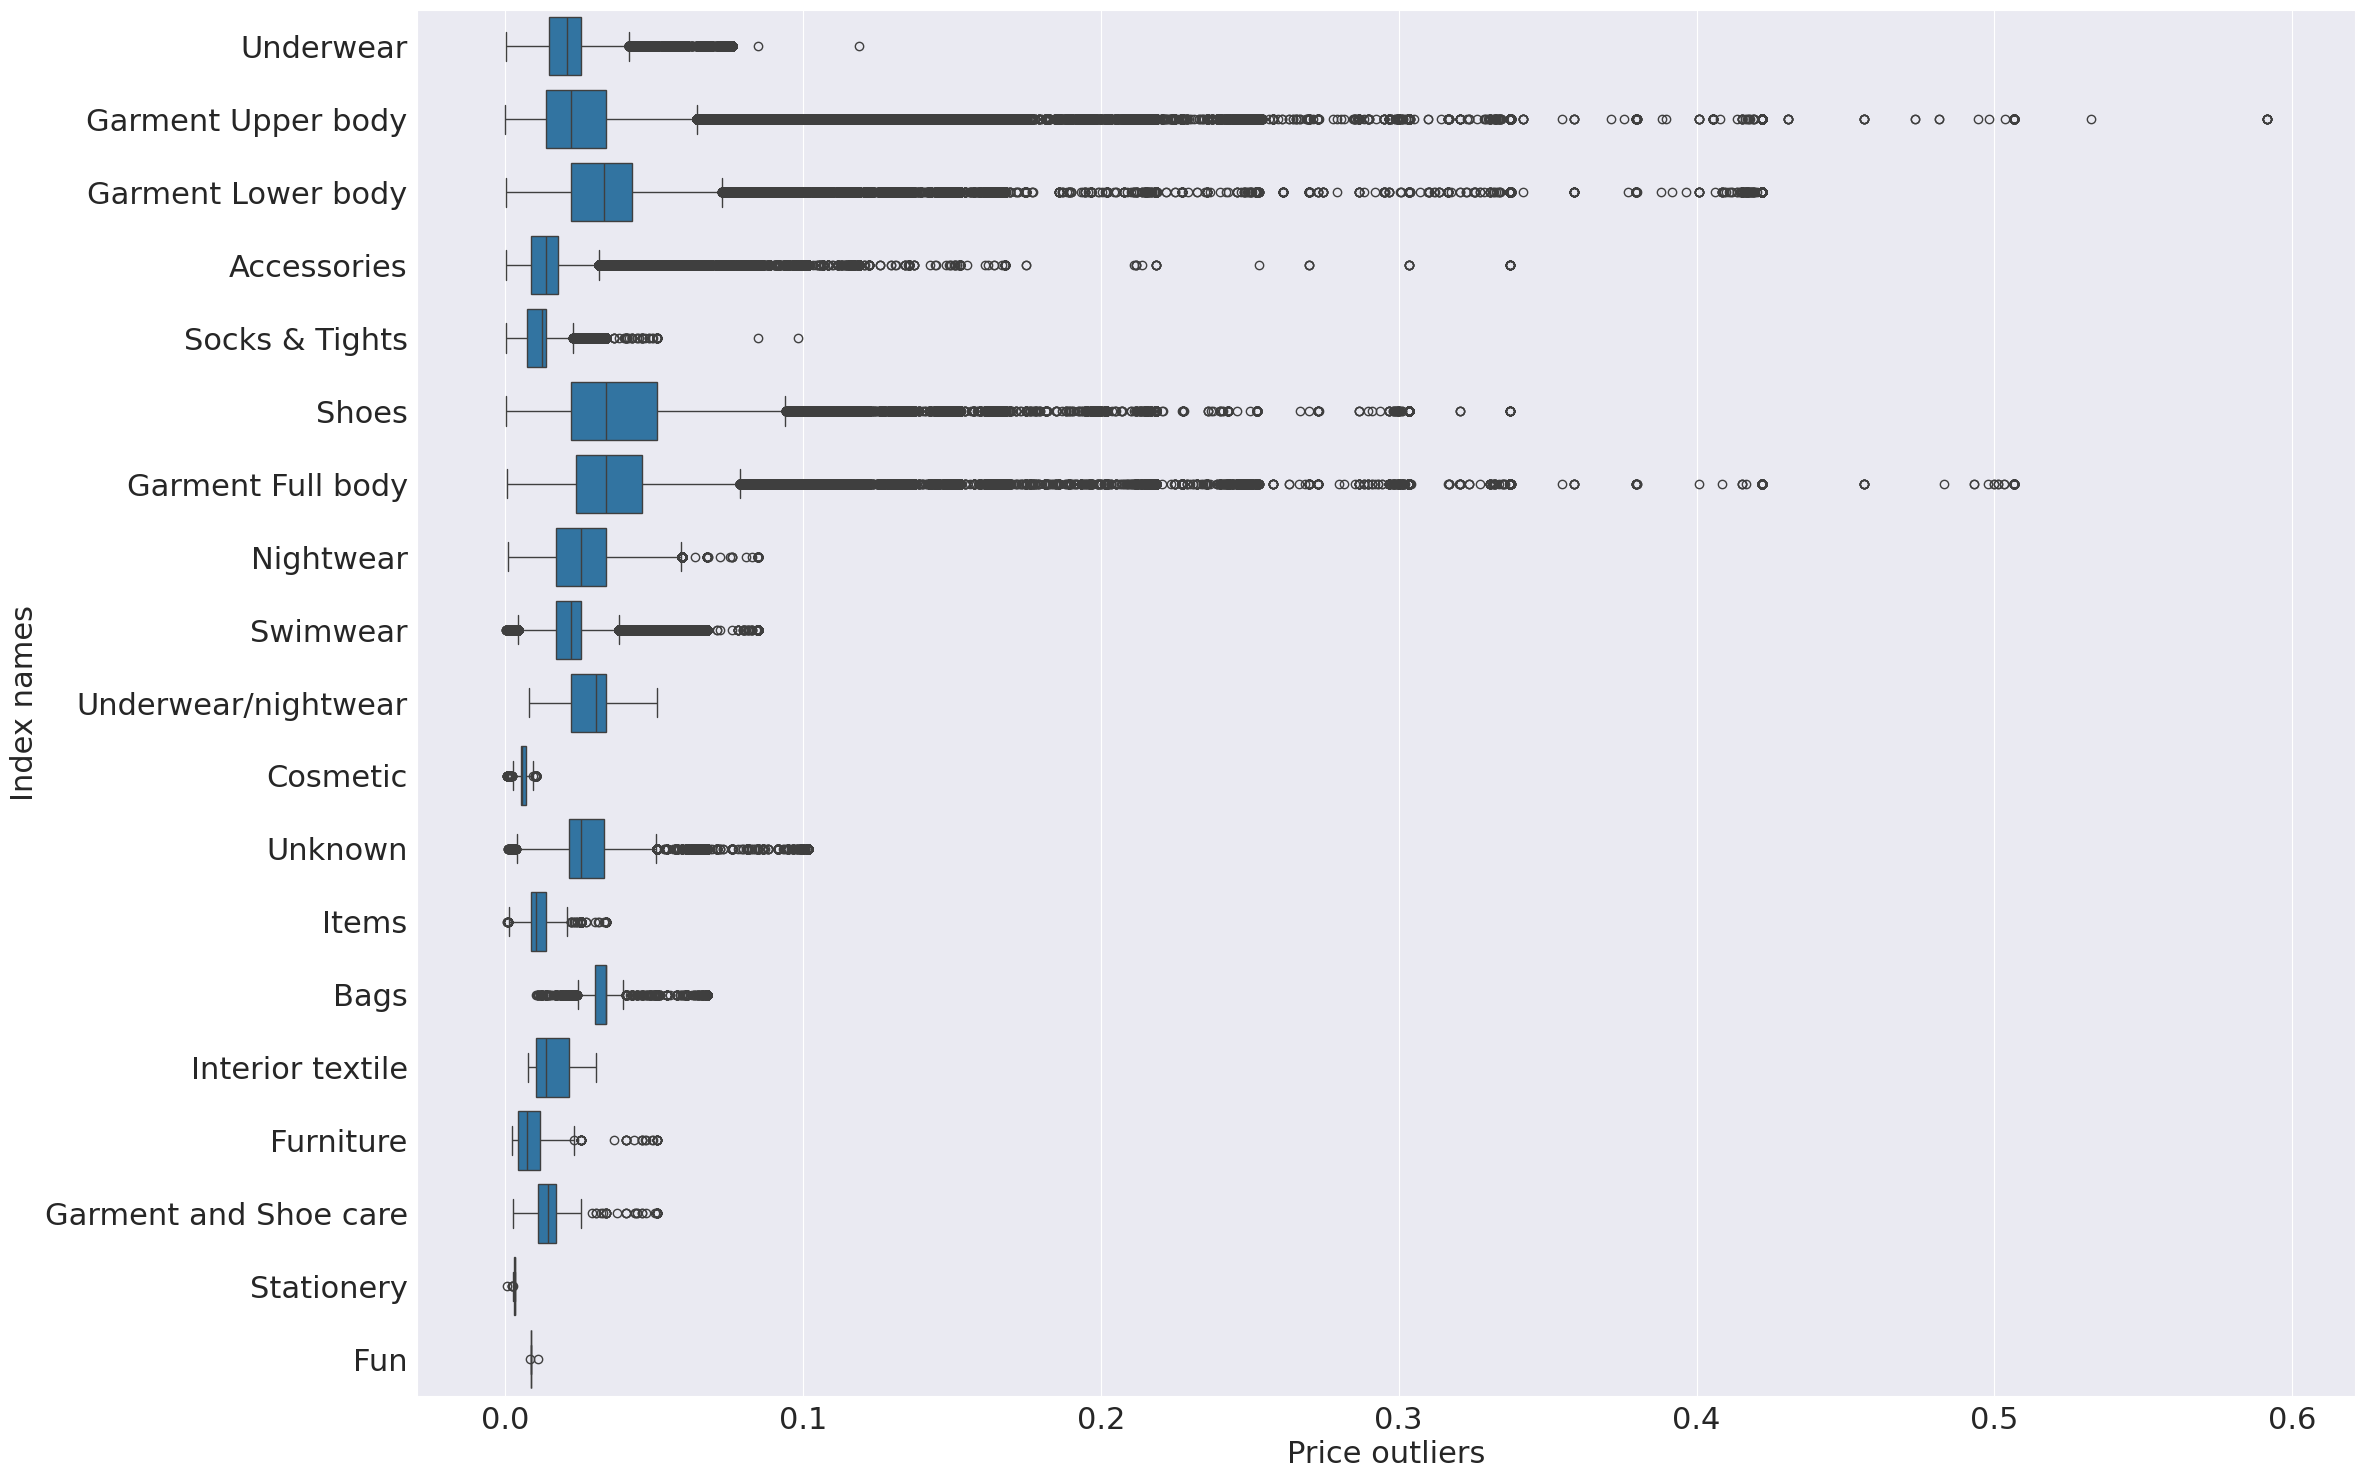

In [93]:
sns.set_style("darkgrid")
f, ax = plt.subplots(figsize=(25,18))
ax = sns.boxplot(data=articles_for_merge, x='price', y='product_group_name')
ax.set_xlabel('Price outliers', fontsize=22)
ax.set_ylabel('Index names', fontsize=22)
ax.xaxis.set_tick_params(labelsize=22)
ax.yaxis.set_tick_params(labelsize=22)

plt.show()

Теперь поизучаем стоимости в категории аксессуаров. И попытаемся найти причину такой разной цены

Большие выбросы можно найти в сумках. Также в шарфах и других аксессуарах.

In [94]:
accessories = articles_for_merge[articles_for_merge['product_group_name'] == 'Accessories']
accessories.head()

,customer_id,article_id,price,t_dat,prod_name,product_type_name,product_group_name,index_name
38,000aa7f0dc06cd7174389e76c9e132a67860c5f65f9706...,553139001,0.0339,2018-09-20,Jenner waist belt,Belt,Accessories,Ladies Accessories
39,000aa7f0dc06cd7174389e76c9e132a67860c5f65f9706...,553139001,0.0339,2018-09-20,Jenner waist belt,Belt,Accessories,Ladies Accessories
54,002b3c0a44a22c45a8d62ea9d2b88d1a89e335f8b84003...,673531001,0.0085,2018-09-20,Keyring fluff,Other accessories,Accessories,"Children Accessories, Swimwear"
62,00401a367c5ac085cb9d4b77c56f3edcabf25153615db9...,633675001,0.0102,2018-09-20,A-band unicorn PU,Hair/alice band,Accessories,"Children Accessories, Swimwear"
82,005c9fb2ba6c49b2098a662f64a9124ef95cbec5fcf4eb...,560783010,0.0051,2018-09-20,Polly pencil case,Bag,Accessories,Divided


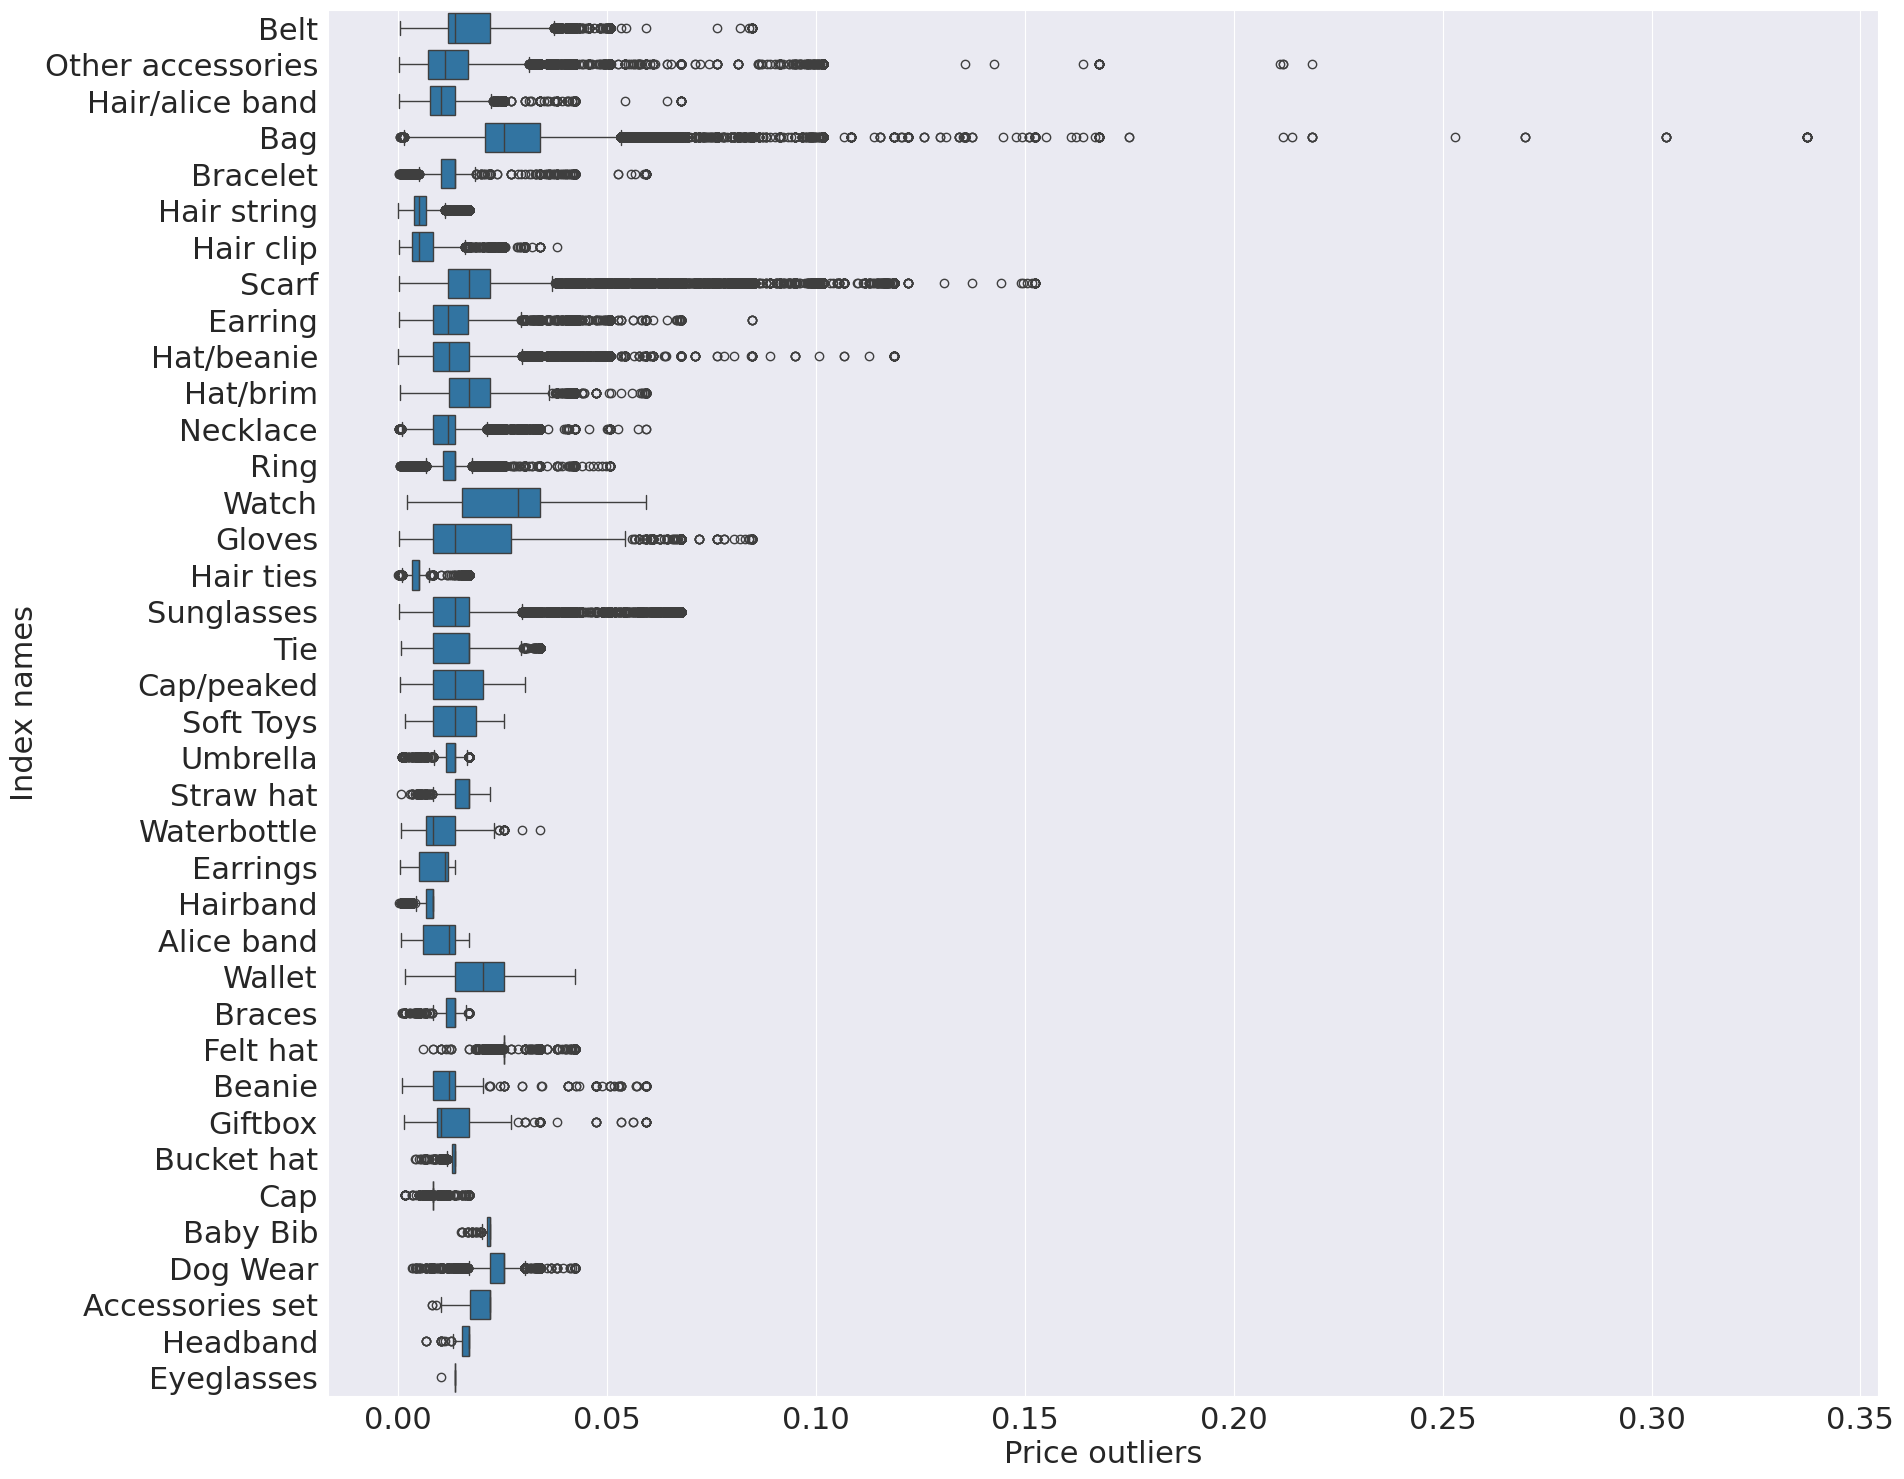

In [95]:
sns.set_style("darkgrid")
f, ax = plt.subplots(figsize=(20, 18))
ax = sns.boxplot(data=accessories, x='price', y='product_type_name')
ax.set_xlabel('Price outliers', fontsize=22)
ax.set_ylabel('Index names', fontsize=22)
ax.xaxis.set_tick_params(labelsize=22)
ax.yaxis.set_tick_params(labelsize=22)

plt.show()

Товар с самой высокой стоимостью находится в женском разделе, а вот с самой низкой стоимостью в детском

In [96]:
articles_index = articles_for_merge[['index_name', 'price']].groupby('index_name').mean()
articles_index = articles_index.sort_values('price')
articles_index

,price
index_name,
Baby Sizes 50-98,0.0175
Children Sizes 92-140,0.0175
"Children Accessories, Swimwear",0.0176
Lingeries/Tights,0.0208
Children Sizes 134-170,0.0219
Ladies Accessories,0.0240
Divided,0.0265
Menswear,0.0275
Sport,0.0288


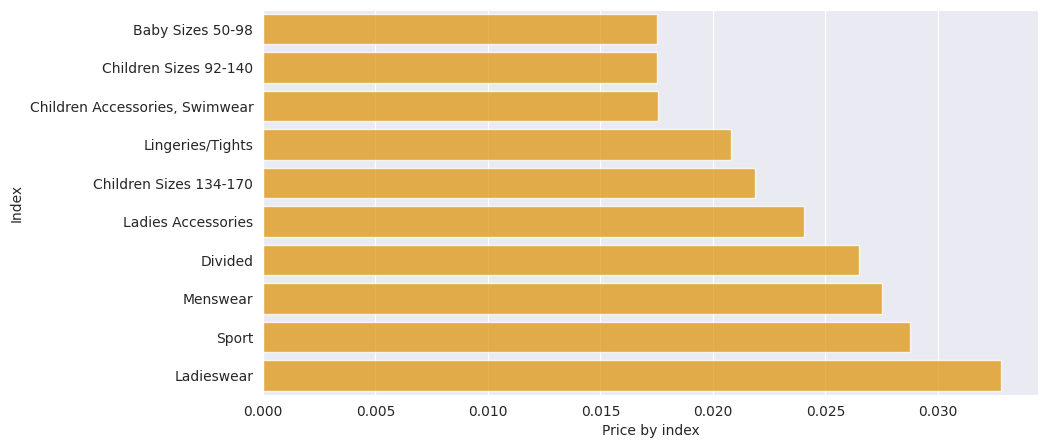

In [97]:
sns.set_style("darkgrid")
f, ax = plt.subplots(figsize=(10,5))
ax = sns.barplot(x=articles_index.price, y=articles_index.index, color='orange', alpha=0.8)
ax.set_xlabel('Price by index')
ax.set_ylabel('Index')
plt.show()

Канцелярские товары имеют наименьшую стоимость, а самая высокая стоисоть у обуви

In [98]:
articles_index = articles_for_merge[['product_group_name', 'price']].groupby('product_group_name').mean()
articles_index = articles_index.sort_values('price')
articles_index

,price
product_group_name,
Stationery,0.0032
Cosmetic,0.0058
Fun,0.0089
Furniture,0.0096
Items,0.0113
Socks & Tights,0.0114
Accessories,0.0156
Interior textile,0.0164
Garment and Shoe care,0.0175


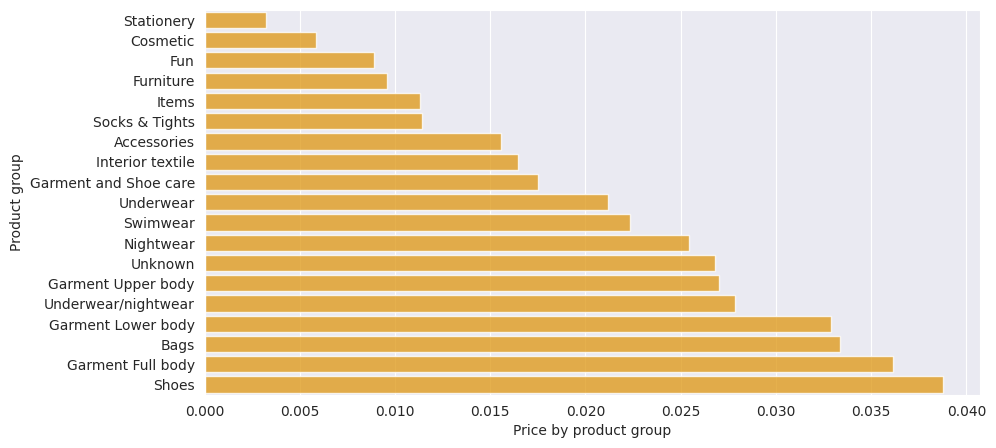

In [99]:
sns.set_style("darkgrid")
f, ax = plt.subplots(figsize=(10,5))
ax = sns.barplot(x=articles_index.price, y=articles_index.index, color='orange', alpha=0.8)
ax.set_xlabel('Price by product group')
ax.set_ylabel('Product group')
plt.show()

**Анализ стоимости от времени**

In [100]:
articles_for_merge['t_dat'] = pd.to_datetime(articles_for_merge['t_dat'])

In [101]:
articles_for_merge_product = articles_for_merge[articles_for_merge.product_group_name == 'Shoes']
series_mean = articles_for_merge_product[['t_dat', 'price']].groupby(pd.Grouper(key="t_dat", freq='M')).mean()
series_mean

/tmp/ipykernel_1572/3129353135.py:2: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  series_mean = articles_for_merge_product[['t_dat', 'price']].groupby(pd.Grouper(key="t_dat", freq='M')).mean()


,price
t_dat,
2018-09-30,0.0434
2018-10-31,0.0417
2018-11-30,0.0455
2018-12-31,0.0442
2019-01-31,0.0438
2019-02-28,0.0405
2019-03-31,0.0402
2019-04-30,0.0375
2019-05-31,0.0366


In [103]:
series_std = articles_for_merge_product[['t_dat', 'price']].groupby(pd.Grouper(key="t_dat", freq='M')).std().fillna(0)
series_std

/tmp/ipykernel_1572/2788820856.py:1: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  series_std = articles_for_merge_product[['t_dat', 'price']].groupby(pd.Grouper(key="t_dat", freq='M')).std().fillna(0)


,price
t_dat,
2018-09-30,0.0277
2018-10-31,0.0268
2018-11-30,0.0265
2018-12-31,0.0277
2019-01-31,0.0271
2019-02-28,0.0232
2019-03-31,0.0201
2019-04-30,0.0199
2019-05-31,0.0202


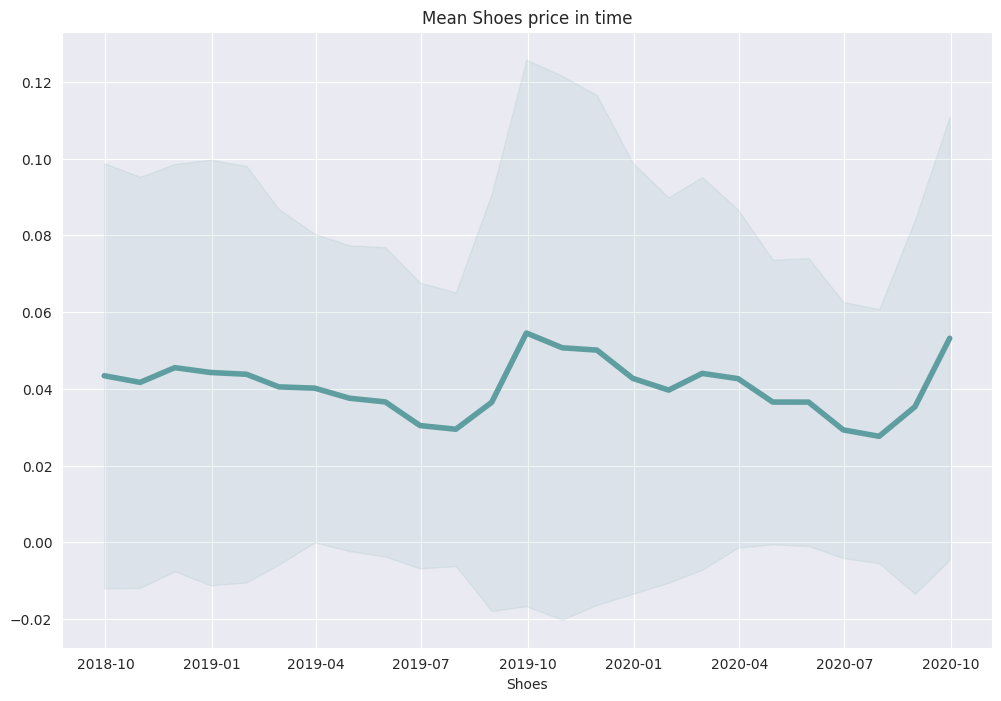

In [104]:
f, ax = plt.subplots(1,1, figsize=(12, 8))

ax.plot(series_mean, linewidth=4, color='cadetblue')
ax.fill_between(series_mean.index,
               (series_mean.values - 2*series_std.values).ravel(),
               (series_mean.values + 2*series_std.values).ravel(),
               color='cadetblue', alpha=.1)

ax.set_title(f'Mean Shoes price in time')
ax.set_xlabel('month')
ax.set_xlabel(f'Shoes');

/tmp/ipykernel_1572/1503712496.py:2: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  series_mean = articles_for_merge_product[['t_dat', 'price']].groupby(pd.Grouper(key="t_dat", freq='M')).mean()
/tmp/ipykernel_1572/1503712496.py:3: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  series_std = articles_for_merge_product[['t_dat', 'price']].groupby(pd.Grouper(key="t_dat", freq='M')).std().fillna(0)


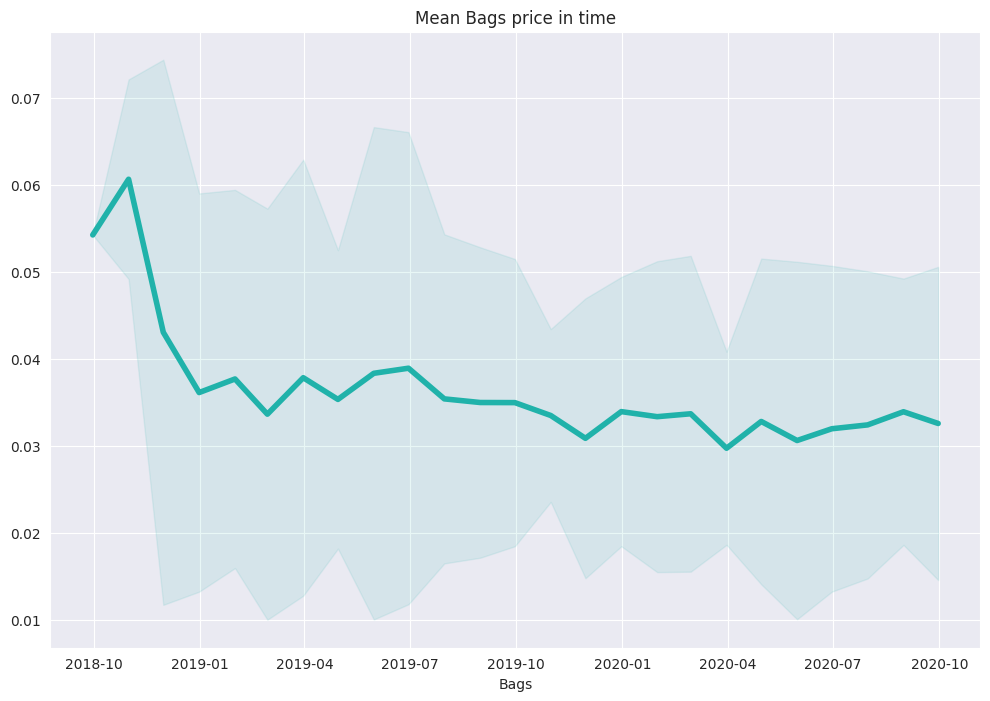

In [106]:
articles_for_merge_product = articles_for_merge[articles_for_merge.product_group_name == 'Bags']
series_mean = articles_for_merge_product[['t_dat', 'price']].groupby(pd.Grouper(key="t_dat", freq='M')).mean()
series_std = articles_for_merge_product[['t_dat', 'price']].groupby(pd.Grouper(key="t_dat", freq='M')).std().fillna(0)

f, ax = plt.subplots(1,1, figsize=(12, 8))

ax.plot(series_mean, linewidth=4, color='lightseagreen')
ax.fill_between(series_mean.index,
               (series_mean.values-2*series_std.values).ravel(),
               (series_mean.values+2*series_std.values).ravel(),
               color='lightseagreen', alpha=.1)

ax.set_title(f'Mean Bags price in time')
ax.set_xlabel('month')
ax.set_xlabel(f'Bags');

## Система рекомендаций (Collaborative Filtering)

<img src='https://www.researchgate.net/profile/Lionel-Ngoupeyou-Tondji/publication/323726564/figure/fig5/AS:631605009846299@1527597777415/Content-based-filtering-vs-Collaborative-filtering-Source.png' width=700>

In [107]:
%%time
transactions.customer_id.unique()

CPU times: user 8.85 s, sys: 165 ms, total: 9.01 s
Wall time: 9.17 s


array(['000058a12d5b43e67d225668fa1f8d618c13dc232df0cad8ffe7ad4a1091e318',
       '00007d2de826758b65a93dd24ce629ed66842531df6699338c5570910a014cc2',
       '00083cda041544b2fbb0e0d2905ad17da7cf1007526fb4c73235dccbbc132280',
       ...,
       'fece2f68864c311a0b5208e2eb735b3dcde7e41461d327bdd033014a27168ce8',
       'fee56cc5315dafb35a4490ccc6f711092cae913550c83251955178bdd1bc6be3',
       'ff5b8a8b26bf93a66290e9bd1b73393ac6a58968a7851941508cce49f5dfa469'],
      dtype=object)

In [108]:
transactions['customer_id_cat'] = transactions.customer_id.astype('category')

In [109]:
%%time
transactions.customer_id_cat.unique()

CPU times: user 386 ms, sys: 727 µs, total: 387 ms
Wall time: 411 ms


['000058a12d5b43e67d225668fa1f8d618c13dc232df0c..., '00007d2de826758b65a93dd24ce629ed66842531df669..., '00083cda041544b2fbb0e0d2905ad17da7cf1007526fb..., '0008968c0d451dbc5a9968da03196fe20051965edde74..., '000aa7f0dc06cd7174389e76c9e132a67860c5f65f970..., ..., 'fe99a0069d6b3c64c2707d0ce53b9311540917471d82d..., 'fecc5f77b5f7ee4570efde9ab05ec94d0de2bf80efb4f..., 'fece2f68864c311a0b5208e2eb735b3dcde7e41461d32..., 'fee56cc5315dafb35a4490ccc6f711092cae913550c83..., 'ff5b8a8b26bf93a66290e9bd1b73393ac6a58968a7851...]
Length: 1362281
Categories (1362281, object): [,
                               '00000dbacae5abe5e23885899a1fa44253a17956c6d1c...,
                               '0000423b00ade91418cceaf3b26c6af3dd342b51fd051...,
                               '000058a12d5b43e67d225668fa1f8d618c13dc232df0c...,
                               '00005ca1c9ed5f5146b52ac8639a40ca9d57aeff4d1bd..., ...,
                               'ffffcd5046a6143d29a04fb8c424ce494a76e5cdf4fab...,
                    

In [110]:
customer_ids_1k = transactions['customer_id_cat'].unique()[:1000]
customer_dict = {id: i for i, id in enumerate(customer_ids_1k)}
len(customer_dict)

1000

In [111]:
transactions_small = transactions[transactions['customer_id_cat'].isin(customer_ids_1k)].copy()
transactions_small.head()

,t_dat,customer_id,article_id,price,sales_channel_id,customer_id_cat
0,2018-09-20,000058a12d5b43e67d225668fa1f8d618c13dc232df0ca...,663713001,0.0508,2,000058a12d5b43e67d225668fa1f8d618c13dc232df0ca...
1,2018-09-20,000058a12d5b43e67d225668fa1f8d618c13dc232df0ca...,541518023,0.0305,2,000058a12d5b43e67d225668fa1f8d618c13dc232df0ca...
2,2018-09-20,00007d2de826758b65a93dd24ce629ed66842531df6699...,505221004,0.0152,2,00007d2de826758b65a93dd24ce629ed66842531df6699...
3,2018-09-20,00007d2de826758b65a93dd24ce629ed66842531df6699...,685687003,0.0169,2,00007d2de826758b65a93dd24ce629ed66842531df6699...
4,2018-09-20,00007d2de826758b65a93dd24ce629ed66842531df6699...,685687004,0.0169,2,00007d2de826758b65a93dd24ce629ed66842531df6699...


In [112]:
tqdm.pandas()

def replace(x):
    try:
        res = customer_dict[x.customer_id_cat]
    except Exception as e:
        print(e)
        res = -1
    return res


transactions_small['customer_id'] = transactions_small.progress_apply(replace, axis=1)
transactions_small.head()

100%|██████████| 72374/72374 [00:02<00:00, 30496.40it/s]


,t_dat,customer_id,article_id,price,sales_channel_id,customer_id_cat
0,2018-09-20,0,663713001,0.0508,2,000058a12d5b43e67d225668fa1f8d618c13dc232df0ca...
1,2018-09-20,0,541518023,0.0305,2,000058a12d5b43e67d225668fa1f8d618c13dc232df0ca...
2,2018-09-20,1,505221004,0.0152,2,00007d2de826758b65a93dd24ce629ed66842531df6699...
3,2018-09-20,1,685687003,0.0169,2,00007d2de826758b65a93dd24ce629ed66842531df6699...
4,2018-09-20,1,685687004,0.0169,2,00007d2de826758b65a93dd24ce629ed66842531df6699...


In [114]:
transactions_small['customer_id'].value_counts()

,count
customer_id,
218,1157
990,1059
379,756
566,652
988,572
...,...
635,1
712,1
211,1


In [115]:
grouped = transactions_small.groupby(['customer_id', 'article_id']).count()['sales_channel_id']
grouped

customer_id  article_id
0            351484002     2
             541518023     1
             578020002     1
             663713001     2
             723529001     1
                          ..
999          861121001     1
             861847005     1
             862167002     2
             863000005     1
             863001001     1
Name: sales_channel_id, Length: 60252, dtype: int64

In [116]:
customer_item_matrix = grouped.unstack('article_id')
customer_item_matrix

article_id,108775015,108775044,108775051,110065001,110065011,111565001,111586001,111593001,111609001,116379047,...,941005001,942064001,942187001,944506001,946282001,946748003,946748004,947060001,947509001,949198001
customer_id,,,,,,,,,,,,,,,,,,,,,
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
996,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
997,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [117]:
customer_item_matrix.shape

(1000, 28632)

In [118]:
customer_item_matrix = customer_item_matrix.applymap(lambda x: 1 if x > 0 else 0)
customer_item_matrix.head()

/tmp/ipykernel_1572/2398350754.py:1: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  customer_item_matrix = customer_item_matrix.applymap(lambda x: 1 if x > 0 else 0)


article_id,108775015,108775044,108775051,110065001,110065011,111565001,111586001,111593001,111609001,116379047,...,941005001,942064001,942187001,944506001,946282001,946748003,946748004,947060001,947509001,949198001
customer_id,,,,,,,,,,,,,,,,,,,,,
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


Косинусная похожесть

<img src='https://drive.google.com/uc?id=1sp8Hfr1H8YKdo6KQHhvK42VPtzzJJczk'>

<img src='https://i.stack.imgur.com/36r1U.png'>

In [119]:
from sklearn.metrics.pairwise import cosine_similarity

cosine_sim = cosine_similarity(customer_item_matrix, customer_item_matrix)
cosine_sim

array([[1.        , 0.        , 0.        , ..., 0.        , 0.        ,
        0.        ],
       [0.        , 1.        , 0.        , ..., 0.        , 0.        ,
        0.01173631],
       [0.        , 0.        , 1.        , ..., 0.        , 0.        ,
        0.        ],
       ...,
       [0.        , 0.        , 0.        , ..., 1.        , 0.        ,
        0.        ],
       [0.        , 0.        , 0.        , ..., 0.        , 1.        ,
        0.        ],
       [0.        , 0.01173631, 0.        , ..., 0.        , 0.        ,
        1.        ]])

In [121]:
cosine_sim.shape

(1000, 1000)

In [123]:
cosine_sim_df = pd.DataFrame(cosine_sim)

cosine_sim_df.columns = customer_item_matrix.index

cosine_sim_df['customer_id'] = customer_item_matrix.index
cosine_sim_df = cosine_sim_df.set_index('customer_id')

cosine_sim_df.head()

customer_id,0,1,2,3,4,5,6,7,8,9,...,990,991,992,993,994,995,996,997,998,999
customer_id,,,,,,,,,,,,,,,,,,,,,
0,1.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,...,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.1226,0.0000,0.0000,0.0000
1,0.0000,1.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,...,0.0151,0.0000,0.0122,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0117
2,0.0000,0.0000,1.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,...,0.0082,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
3,0.0000,0.0000,0.0000,1.0000,0.0221,0.0000,0.0000,0.0215,0.0000,0.0000,...,0.0105,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
4,0.0000,0.0000,0.0000,0.0221,1.0000,0.0264,0.0000,0.0000,0.0000,0.0438,...,0.0066,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0566,0.0000,0.0000


In [124]:
# На примере эталонного покупателя находим тех покупателей, которые близки к нему по косинусной мере
cosine_sim_df.loc[4].sort_values(ascending=False)

,4
customer_id,
4,1.0000
899,0.1443
460,0.1179
101,0.1000
972,0.0925
...,...
423,0.0000
424,0.0000
425,0.0000


In [125]:
# Определяем перечень уникальных покупок нашего эталонного покупателя
A = customer_item_matrix.loc[4]
items_bought_by_A = A[A > 0].index.tolist()
items_bought_by_A

[377277001,
 501820043,
 553139001,
 589017001,
 607983004,
 631848002,
 640639001,
 663498003,
 664421002,
 671505001,
 674681001,
 676827002,
 680187001,
 680912006,
 680912009,
 685687002,
 692454002,
 693497001,
 700819006,
 706016001,
 706016002,
 706016003,
 713349001,
 717490002,
 728162001,
 733044001,
 743049002,
 748355006,
 758049001,
 758050001,
 758060001,
 758064001,
 796210001,
 851996001,
 868164002,
 903309001]

In [127]:
# Определяем перечень уникальных покупок покупателя наиболее близкого к нашему
B = customer_item_matrix.loc[899]
items_bought_by_B = B[B > 0].index.tolist()
items_bought_by_B

[595779011,
 705988005,
 708379004,
 713700001,
 718623005,
 746329003,
 758040001,
 758043001,
 758049001,
 758050001,
 758064001,
 758125001]

In [128]:
# Отбираем те покупки, которые есть у близкого к нашему покупателю, но нет у нашего покупателя
items_to_recommend_to_A = set(items_bought_by_B) - set(items_bought_by_A)
items_to_recommend_to_A

{595779011,
 705988005,
 708379004,
 713700001,
 718623005,
 746329003,
 758040001,
 758043001,
 758125001}

In [131]:
# Выводим перечень товаров, рекомендованных для нашего эталонного покупателя
articles[articles['article_id'].isin(items_to_recommend_to_A)][['article_id', 'prod_name', 'product_type_name']]

,article_id,prod_name,product_type_name
21890,595779011,Offy sweater,Sweater
53880,705988005,Molly HW Ankle TRS,Trousers
54760,708379004,Simone,Top
56254,713700001,VERA LACE TOP,Blouse
58066,718623005,PHILIPPA SHIRT,Shirt
66030,746329003,Andy skirt,Skirt
69757,758040001,LS Emmy Padded Triangle Top,Bikini top
69758,758043001,LS Emmy Tanga,Swimwear bottom
69771,758125001,LS Sarong,Sarong
